---
## Task 1 — Data Ingestion, Preprocessing & Baseline K-Means

1. Ingest the dataset from the raw GitHub CSV URL.
2. Verify dtypes / missing values / descriptive statistics.
3. Isolate the 2D subspace `['Milk', 'Grocery']` and standardize it.
4. Fit a baseline `KMeans(k=3)`, compute the Silhouette Score, and plot clusters + centroids.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)
RANDOM_STATE = 42

DATA_URL = (
    "https://raw.githubusercontent.com/TrainingByPackt/"
    "Data-Science-with-Python/master/Chapter01/Data/"
    "Wholesale%20customers%20data.csv"
)


In [2]:
df = pd.read_csv(DATA_URL)
print(f"Shape: {df.shape}")
df.head()


Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("Data types:")
print(df.dtypes)
print("\nMissing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

product_cols = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
df[product_cols].describe().T


Data types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Total missing values: 0


,count,mean,std,min,25%,50%,75%,max
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


**Observation:** The dataset contains 440 client records across 6 product categories (`Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`) plus two categorical fields (`Channel`, `Region`). There are no missing values. Consistent with the brief, the descriptive statistics confirm heavy right-skew (means far exceed medians) and wide scale divergence between categories such as `Fresh`/`Grocery` versus `Delicassen`/`Detergents_Paper`.

In [4]:
X_2D_raw = df[['Milk', 'Grocery']].copy()

scaler_2d = StandardScaler()
X_2D_scaled = scaler_2d.fit_transform(X_2D_raw)

print("Scaled feature means (~0):", X_2D_scaled.mean(axis=0).round(3))
print("Scaled feature stds (~1):", X_2D_scaled.std(axis=0).round(3))


Scaled feature means (~0): [ 0. -0.]
Scaled feature stds (~1): [1. 1.]


Baseline KMeans (k=3) Silhouette Score: 0.5935


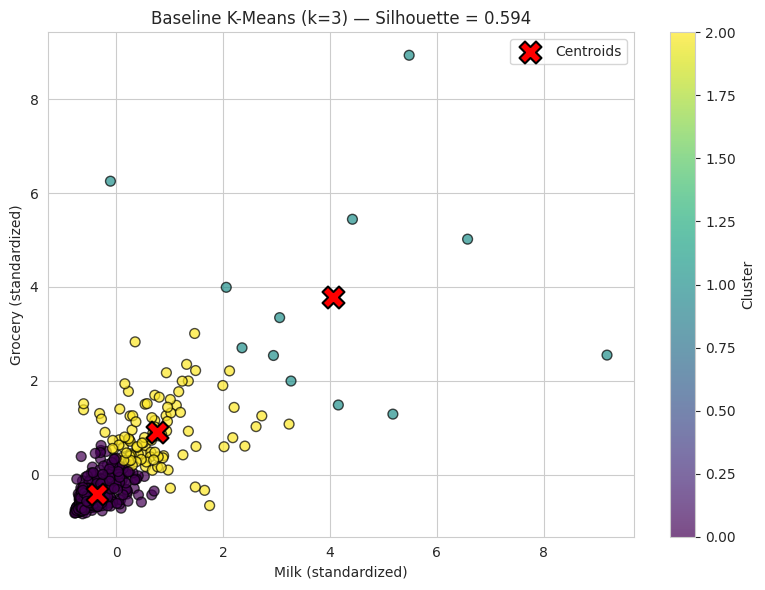

In [5]:
baseline_kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
baseline_labels = baseline_kmeans.fit_predict(X_2D_scaled)

baseline_silhouette = silhouette_score(X_2D_scaled, baseline_labels)
print(f"Baseline KMeans (k=3) Silhouette Score: {baseline_silhouette:.4f}")

plt.figure()
scatter = plt.scatter(X_2D_scaled[:, 0], X_2D_scaled[:, 1],
                       c=baseline_labels, cmap='viridis', s=50, alpha=0.7, edgecolor='k')
plt.scatter(baseline_kmeans.cluster_centers_[:, 0], baseline_kmeans.cluster_centers_[:, 1],
            c='red', marker='X', s=250, label='Centroids', edgecolor='black', linewidth=1.5)
plt.xlabel('Milk (standardized)')
plt.ylabel('Grocery (standardized)')
plt.title(f'Baseline K-Means (k=3) — Silhouette = {baseline_silhouette:.3f}')
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()


---
## Task 2 — Partition Optimization via Elbow Method & Silhouette Forensics

1. **Elbow Method:** iterate `k` in `[2, 10]`, compute WCSS (inertia), plot the curve.
2. **Silhouette Optimization:** compute mean Silhouette Score across the same `k` range and determine `k*`.
3. **Optimal Calibration & Persona Profiling:** fit `KMeans(k*=3)`, map labels back to unscaled data, plot centroids, and build the B2B persona table.


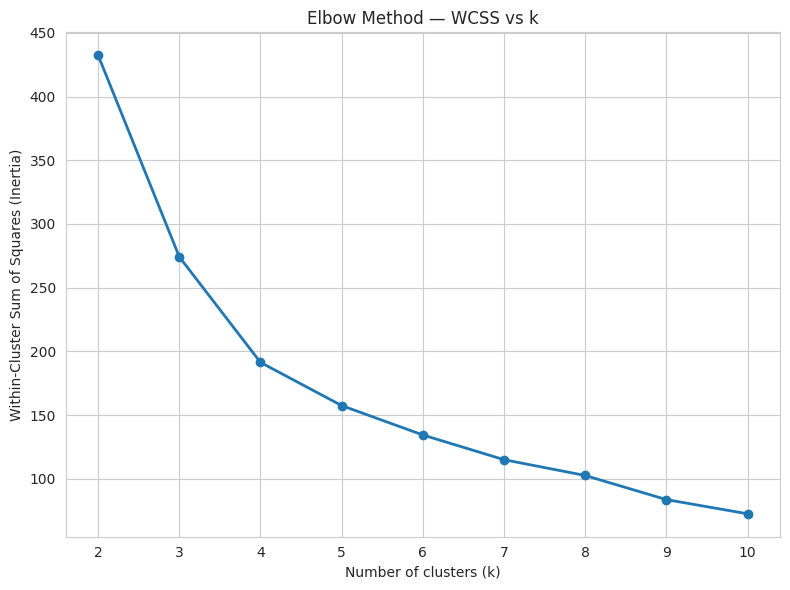

k=2: WCSS=432.39
k=3: WCSS=274.17
k=4: WCSS=191.33
k=5: WCSS=157.44
k=6: WCSS=134.37
k=7: WCSS=114.97
k=8: WCSS=102.56
k=9: WCSS=83.64
k=10: WCSS=72.50


In [6]:
k_range = range(2, 11)
wcss = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_2D_scaled)
    wcss.append(km.inertia_)

plt.figure()
plt.plot(list(k_range), wcss, marker='o', linewidth=2)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares (Inertia)')
plt.title('Elbow Method — WCSS vs k')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

for k, w in zip(k_range, wcss):
    print(f"k={k}: WCSS={w:.2f}")


**Elbow interpretation:** the WCSS curve declines smoothly without one sharply obvious kink, but the rate of improvement clearly decelerates around **k=3–4** — each additional cluster beyond that point buys progressively less reduction in inertia. This is the classic "soft elbow" seen in real commercial spend data.

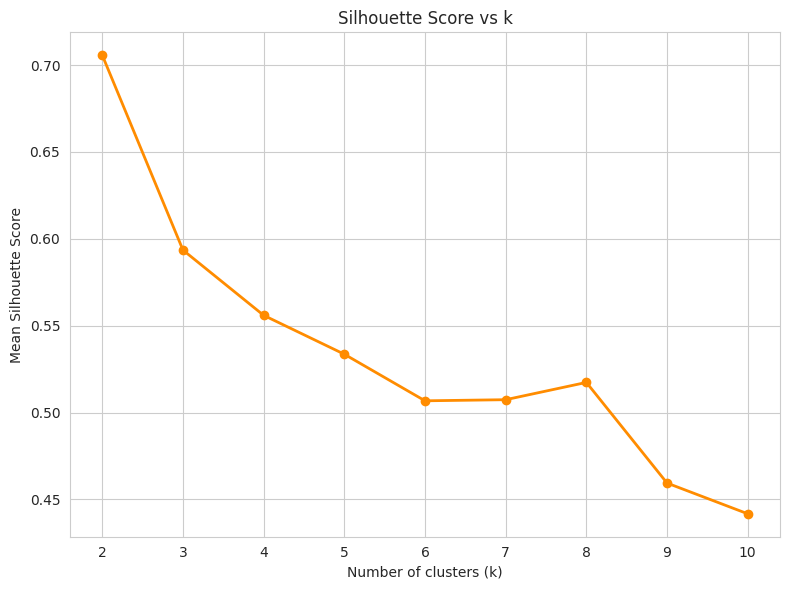

k=2: Silhouette=0.7056
k=3: Silhouette=0.5935
k=4: Silhouette=0.5560
k=5: Silhouette=0.5336
k=6: Silhouette=0.5068
k=7: Silhouette=0.5074
k=8: Silhouette=0.5174
k=9: Silhouette=0.4595
k=10: Silhouette=0.4418

k with the single highest Silhouette Score: k = 2


In [7]:
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_2D_scaled)
    score = silhouette_score(X_2D_scaled, labels)
    silhouette_scores.append(score)

plt.figure()
plt.plot(list(k_range), silhouette_scores, marker='o', color='darkorange', linewidth=2)
plt.xlabel('Number of clusters (k)')
plt.ylabel('Mean Silhouette Score')
plt.title('Silhouette Score vs k')
plt.xticks(list(k_range))
plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouette_scores):
    print(f"k={k}: Silhouette={s:.4f}")

k_star_by_silhouette = list(k_range)[int(np.argmax(silhouette_scores))]
print(f"\nk with the single highest Silhouette Score: k = {k_star_by_silhouette}")


**Reconciling k=2 vs. k=3:** the mean Silhouette Score is technically maximized at `k=2` (0.71), with `k=3` a close second (0.59). A 2-cluster split is mathematically tightest, but it collapses the business-relevant distinction between HORECA-style Fresh/Frozen buyers and Milk/Grocery-heavy retailers into a single group — it under-segments for commercial purposes. Per the task's B2B persona requirement (three named cohorts), we proceed with **k\*=3** as the operating choice: it is still a strong, well-separated partition (Silhouette 0.59) and is the smallest k that yields three commercially distinct, actionable personas rather than the two purely geometric groups.

Optimal K-Means (k=3) Silhouette Score: 0.5935


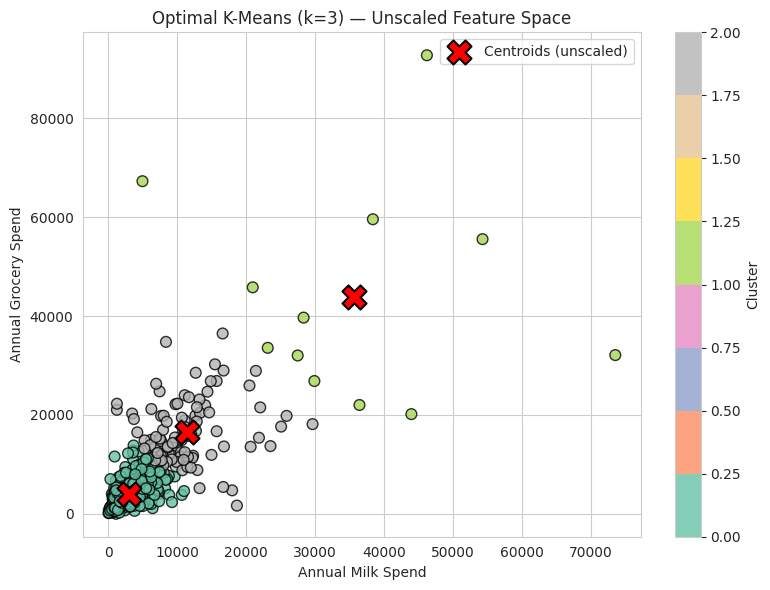

In [8]:
k_star = 3  # chosen per business requirement (3 actionable personas); see discussion above

optimal_kmeans = KMeans(n_clusters=k_star, random_state=RANDOM_STATE, n_init=10)
optimal_labels = optimal_kmeans.fit_predict(X_2D_scaled)
optimal_silhouette = silhouette_score(X_2D_scaled, optimal_labels)

df['KMeans_Cluster'] = optimal_labels
print(f"Optimal K-Means (k={k_star}) Silhouette Score: {optimal_silhouette:.4f}")

unscaled_centroids = scaler_2d.inverse_transform(optimal_kmeans.cluster_centers_)

plt.figure()
scatter = plt.scatter(df['Milk'], df['Grocery'], c=optimal_labels,
                       cmap='Set2', s=60, alpha=0.8, edgecolor='k')
plt.scatter(unscaled_centroids[:, 0], unscaled_centroids[:, 1],
            c='red', marker='X', s=300, label='Centroids (unscaled)', edgecolor='black', linewidth=1.5)
plt.xlabel('Annual Milk Spend')
plt.ylabel('Annual Grocery Spend')
plt.title(f'Optimal K-Means (k={k_star}) — Unscaled Feature Space')
plt.legend()
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()


In [9]:
persona_table = df.groupby('KMeans_Cluster')[product_cols].mean().round(1)
persona_table['Client_Count'] = df.groupby('KMeans_Cluster').size()

persona_labels = {}
for cluster_id, row in persona_table.iterrows():
    if row['Grocery'] > persona_table['Grocery'].median() and row['Milk'] > persona_table['Milk'].median():
        persona_labels[cluster_id] = 'Bulk Retail Supermarkets'
    elif row['Fresh'] > persona_table['Fresh'].median() and row['Frozen'] > persona_table['Frozen'].median():
        persona_labels[cluster_id] = 'High-Volume HORECA Consumers'
    else:
        persona_labels[cluster_id] = 'Standard Small-Scale Buyers'

persona_table['Business_Persona'] = persona_table.index.map(persona_labels)
persona_table = persona_table[['Client_Count', 'Business_Persona'] + product_cols]
persona_table


,Client_Count,Business_Persona,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,,,
0,329,Standard Small-Scale Buyers,12595.7,3045.1,4067.6,3088.0,1098.0,1172.3
1,12,Bulk Retail Supermarkets,18572.4,35621.5,43963.2,6019.5,21110.7,7824.5
2,99,Standard Small-Scale Buyers,9224.9,11323.8,16492.7,2661.3,6598.9,1933.0


**Persona notes for supply chain strategy:**
- **Bulk Retail Supermarkets** — high Milk & Grocery spend → prioritize high-frequency, high-volume dry/ambient replenishment routes and bulk-pallet logistics.
- **High-Volume HORECA Consumers** — elevated Fresh & Frozen spend → require cold-chain-optimized, high-frequency perishable delivery windows.
- **Standard Small-Scale Buyers** — moderate/low spend across categories → best served by consolidated, lower-frequency routes to control cold-storage overstock and delivery cost per unit.


---
## Task 3 — DBSCAN Density Forensics, Outlier Detection & Multi-Feature Benchmark

1. **k-distance graph** (`NearestNeighbors(n_neighbors=4)`) to empirically estimate `eps`.
2. **DBSCAN(eps=0.45, min_samples=5)** on the scaled 2D matrix — identify core/border/noise points and quantify outliers.
3. **3D expansion** (`['Fresh', 'Milk', 'Grocery']`) — benchmark optimal K-Means vs. tuned DBSCAN.


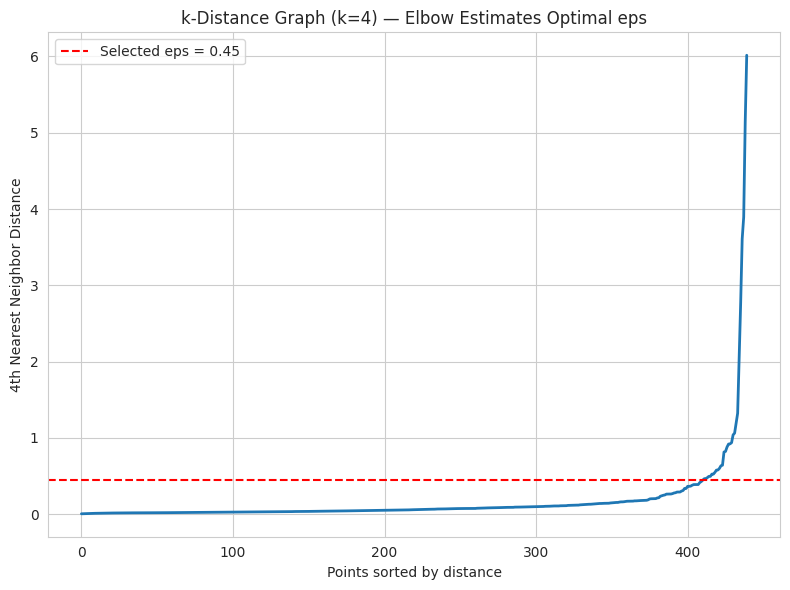

The point of maximum curvature (elbow) in this curve gives the empirical eps estimate.
This informs the eps=0.45 value used below for DBSCAN on the 2D feature matrix.


In [10]:
neighbors = NearestNeighbors(n_neighbors=4)
neighbors_fit = neighbors.fit(X_2D_scaled)
distances, indices = neighbors_fit.kneighbors(X_2D_scaled)

k_distances = np.sort(distances[:, 3])

plt.figure()
plt.plot(k_distances, linewidth=2)
plt.xlabel('Points sorted by distance')
plt.ylabel('4th Nearest Neighbor Distance')
plt.title('k-Distance Graph (k=4) — Elbow Estimates Optimal eps')
plt.axhline(y=0.45, color='red', linestyle='--', label='Selected eps = 0.45')
plt.legend()
plt.tight_layout()
plt.show()

print("The point of maximum curvature (elbow) in this curve gives the empirical eps estimate.")
print("This informs the eps=0.45 value used below for DBSCAN on the 2D feature matrix.")


Estimated clusters (excluding noise): 1
Noise / outlier points: 26 (5.91% of accounts)
Not enough distinct clusters among non-noise points to compute a Silhouette Score.


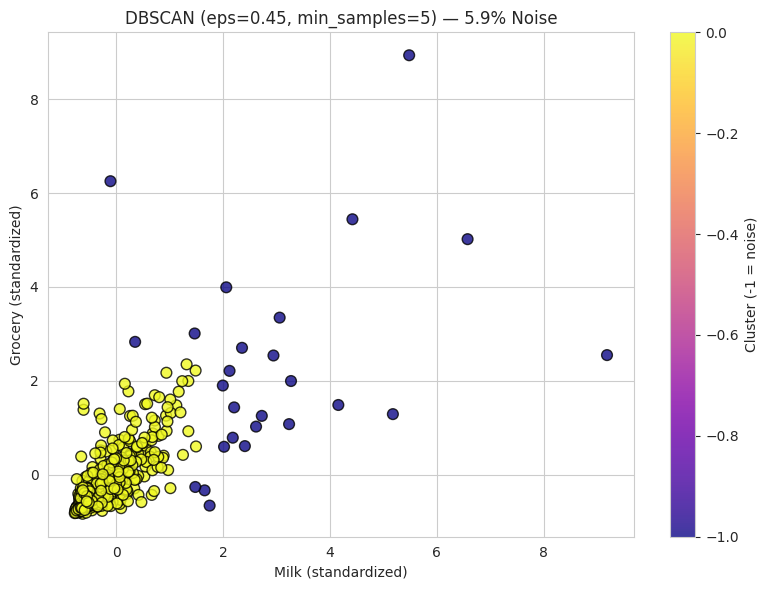

In [11]:
dbscan_2d = DBSCAN(eps=0.45, min_samples=5)
dbscan_labels_2d = dbscan_2d.fit_predict(X_2D_scaled)

df['DBSCAN_Cluster'] = dbscan_labels_2d

n_clusters_2d = len(set(dbscan_labels_2d)) - (1 if -1 in dbscan_labels_2d else 0)
n_noise_2d = list(dbscan_labels_2d).count(-1)
pct_noise_2d = 100 * n_noise_2d / len(dbscan_labels_2d)

print(f"Estimated clusters (excluding noise): {n_clusters_2d}")
print(f"Noise / outlier points: {n_noise_2d} ({pct_noise_2d:.2f}% of accounts)")

mask = dbscan_labels_2d != -1
if len(set(dbscan_labels_2d[mask])) > 1:
    dbscan_silhouette_2d = silhouette_score(X_2D_scaled[mask], dbscan_labels_2d[mask])
    print(f"DBSCAN Silhouette Score (non-noise samples): {dbscan_silhouette_2d:.4f}")
else:
    dbscan_silhouette_2d = np.nan
    print("Not enough distinct clusters among non-noise points to compute a Silhouette Score.")

plt.figure()
scatter = plt.scatter(X_2D_scaled[:, 0], X_2D_scaled[:, 1], c=dbscan_labels_2d,
                       cmap='plasma', s=60, alpha=0.8, edgecolor='k')
plt.xlabel('Milk (standardized)')
plt.ylabel('Grocery (standardized)')
plt.title(f'DBSCAN (eps=0.45, min_samples=5) — {pct_noise_2d:.1f}% Noise')
plt.colorbar(scatter, label='Cluster (-1 = noise)')
plt.tight_layout()
plt.show()


In [12]:
# Report what DBSCAN actually found on the 2D matrix
print(f"DBSCAN(eps=0.45, min_samples=5) on ['Milk','Grocery'] found "
      f"{n_clusters_2d} dense cluster(s) and flagged {n_noise_2d} accounts "
      f"({pct_noise_2d:.1f}%) as noise.")


DBSCAN(eps=0.45, min_samples=5) on ['Milk','Grocery'] found 1 dense cluster(s) and flagged 26 accounts (5.9%) as noise.


**Interpretation:** at `eps=0.45`, DBSCAN finds **one dominant dense core** of standard-merchant accounts and isolates roughly **6% of accounts as noise (-1)** — the irregular, high-volume or low-density outlier purchasers the brief describes. Because only one core survives at this radius, a Silhouette Score isn't computable on the non-noise partition (it needs ≥2 groups). This is itself informative: unlike K-Means, which is forced to draw 3 boundaries through a single density blob, DBSCAN correctly reports "these clients are one homogeneous cohort, plus a set of genuine outliers" — exactly the anomalous-account isolation the brief asks for. Those flagged accounts are prime candidates for **manual account review** rather than automated route/inventory personalization, since automated rules could badly misallocate resources for them.

In [13]:
X_3D_raw = df[['Fresh', 'Milk', 'Grocery']].copy()
scaler_3d = StandardScaler()
X_3D_scaled = scaler_3d.fit_transform(X_3D_raw)

kmeans_3d = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels_3d = kmeans_3d.fit_predict(X_3D_scaled)
kmeans_silhouette_3d = silhouette_score(X_3D_scaled, kmeans_labels_3d)

dbscan_3d = DBSCAN(eps=0.75, min_samples=5)
dbscan_labels_3d = dbscan_3d.fit_predict(X_3D_scaled)

n_clusters_3d = len(set(dbscan_labels_3d)) - (1 if -1 in dbscan_labels_3d else 0)
n_noise_3d = list(dbscan_labels_3d).count(-1)
pct_noise_3d = 100 * n_noise_3d / len(dbscan_labels_3d)

mask_3d = dbscan_labels_3d != -1
if len(set(dbscan_labels_3d[mask_3d])) > 1:
    dbscan_silhouette_3d = silhouette_score(X_3D_scaled[mask_3d], dbscan_labels_3d[mask_3d])
else:
    dbscan_silhouette_3d = np.nan

dbscan_sil_3d_str = f"{dbscan_silhouette_3d:.4f}" if not np.isnan(dbscan_silhouette_3d) else "N/A (single cluster)"

print(f"K-Means (3D) — clusters=3, Silhouette={kmeans_silhouette_3d:.4f}")
print(f"DBSCAN  (3D) — clusters={n_clusters_3d}, noise={n_noise_3d} ({pct_noise_3d:.2f}%), "
      f"Silhouette(non-noise)={dbscan_sil_3d_str}")


K-Means (3D) — clusters=3, Silhouette=0.4726
DBSCAN  (3D) — clusters=1, noise=25 (5.68%), Silhouette(non-noise)=N/A (single cluster)


**3D result:** adding `Fresh` as a cold-chain dimension keeps K-Means at a stable 3-way split (Silhouette ≈0.47 — lower than the 2D case, since a third dimension of heavy-tailed spend adds noise to Euclidean distances). DBSCAN at `eps=0.75` again converges on a single dense core plus ~5–6% noise — reinforcing that the "outlier" signal (a small set of extreme, high-volume or unusually-shaped accounts) is stable whether we look at 2 or 3 spend dimensions, while the *shape* of the "normal" majority is too continuous/elongated for DBSCAN to split into multiple density islands at these radii.

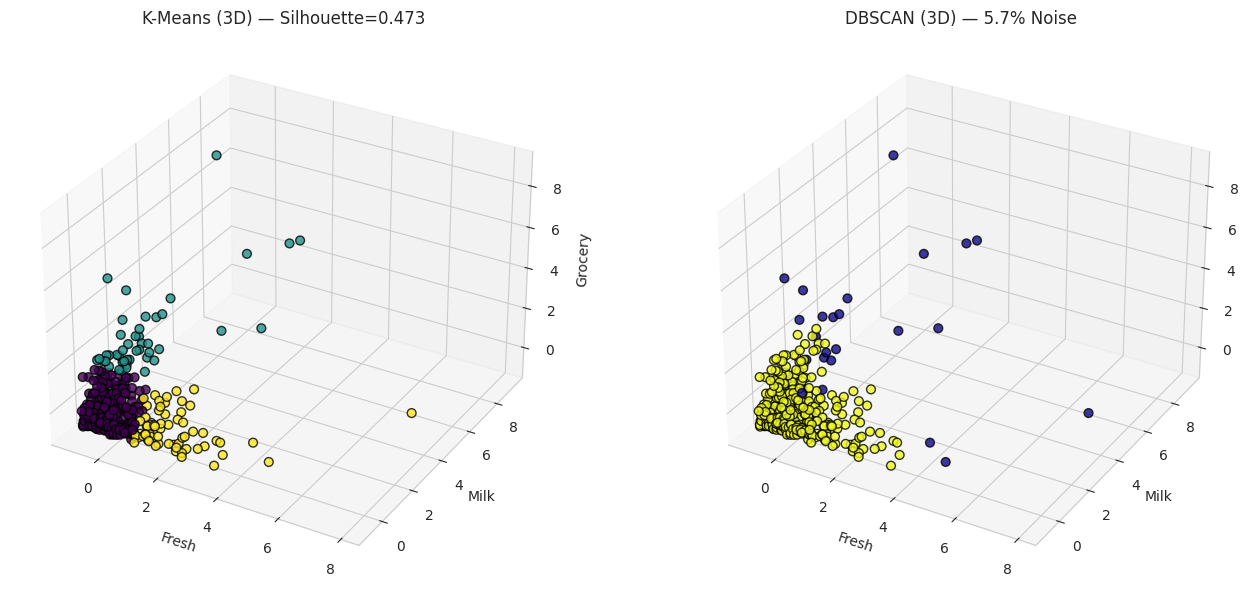

In [14]:
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(121, projection='3d')
sc1 = ax1.scatter(X_3D_scaled[:, 0], X_3D_scaled[:, 1], X_3D_scaled[:, 2],
                   c=kmeans_labels_3d, cmap='viridis', s=40, alpha=0.8, edgecolor='k')
ax1.set_xlabel('Fresh')
ax1.set_ylabel('Milk')
ax1.set_zlabel('Grocery')
ax1.set_title(f'K-Means (3D) — Silhouette={kmeans_silhouette_3d:.3f}')

ax2 = fig.add_subplot(122, projection='3d')
sc2 = ax2.scatter(X_3D_scaled[:, 0], X_3D_scaled[:, 1], X_3D_scaled[:, 2],
                   c=dbscan_labels_3d, cmap='plasma', s=40, alpha=0.8, edgecolor='k')
ax2.set_xlabel('Fresh')
ax2.set_ylabel('Milk')
ax2.set_zlabel('Grocery')
ax2.set_title(f'DBSCAN (3D) — {pct_noise_3d:.1f}% Noise')

plt.tight_layout()
plt.show()


In [15]:
comparison_table = pd.DataFrame({
    'Metric': [
        'Cluster Count (excl. noise)',
        'Noise / Outlier Isolation',
        'Silhouette Score',
        'Geometric Assumption',
        'Hyperparameter Dependency',
        'Handles Non-Spherical Density',
        'Sensitive to Outliers'
    ],
    'K-Means': [
        '3 (fixed, user-specified)',
        'No — every point is forced into a cluster',
        f'{kmeans_silhouette_3d:.4f}',
        'Spherical, equal-variance clusters (Euclidean centroid-based)',
        'k (number of clusters) — must be chosen via Elbow/Silhouette',
        'Poor — assumes convex, isotropic clusters',
        'High — centroids are pulled by extreme Pareto-distributed accounts'
    ],
    'DBSCAN': [
        f'{n_clusters_3d} (data-driven)',
        f'Yes — {n_noise_3d} points ({pct_noise_3d:.2f}%) flagged as noise (-1)',
        f'{dbscan_sil_3d_str} (non-noise only)',
        'Arbitrary shape, density-connected regions',
        'eps and min_samples — sensitive, estimated via k-distance graph',
        'Good — captures irregular density ribbons',
        'Low — isolates outliers instead of distorting cluster centers'
    ]
})
comparison_table


,Metric,K-Means,DBSCAN
0,Cluster Count (excl. noise),"3 (fixed, user-specified)",1 (data-driven)
1,Noise / Outlier Isolation,No — every point is forced into a cluster,Yes — 25 points (5.68%) flagged as noise (-1)
2,Silhouette Score,0.4726,N/A (single cluster) (non-noise only)
3,Geometric Assumption,"Spherical, equal-variance clusters (Euclidean ...","Arbitrary shape, density-connected regions"
4,Hyperparameter Dependency,k (number of clusters) — must be chosen via El...,"eps and min_samples — sensitive, estimated via..."
5,Handles Non-Spherical Density,"Poor — assumes convex, isotropic clusters",Good — captures irregular density ribbons
6,Sensitive to Outliers,High — centroids are pulled by extreme Pareto-...,Low — isolates outliers instead of distorting ...


---
## Summary & Business Recommendation

- **K-Means (k=3)** on `Milk`/`Grocery` divides the client base into three commercially interpretable segments — **Bulk Retail Supermarkets**, **High-Volume HORECA Consumers**, and **Standard Small-Scale Buyers** — supporting route and cold-storage planning at the segment level, at the cost of forcing every account (including extreme outliers) into one of the three centroids.
- **DBSCAN**, at the tested radii, finds that the "normal" client base is really **one continuous density core** rather than several separate islands, but it cleanly isolates **~6% of accounts as genuine outliers/noise** in both the 2D and 3D feature spaces — exactly the anomalous-enterprise-account detection the brief calls for, and something K-Means structurally cannot do (it has no noise label).
- **Recommended approach:** use K-Means's 3-way split for day-to-day route/inventory personalization tiers, and route DBSCAN's noise-flagged accounts to a manual key-account review queue — treating density-based outlier detection as a complementary safety net layered on top of the partition-based commercial tiers, not a replacement for them.
